> **이 노트북의 출력은 예전에 나눠 받아 합친 데이터(`data\통합_202611`, 2026-11-02 실행) 결과다. 새 데이터로 다시 돌리지 않았다.** 새 데이터의 비중·지표·요인 순서 실험은 `확장연구_20261103.ipynb`가 한꺼번에 한다(같은 실험을 더 넓게). 이 노트북의 요약표용 결과는 `결과_월수익률/_예전_20261102/`로 옮겼다.

# 이로운: 비중 바꾸기 (마법공식 상위 30종목)
연구_틀(`연구_틀.ipynb`)을 복사해 **0번(실험 기록)과 3번(설정) 칸만** 바꾸고, 10번부터 실험 칸을 더했다. 공통 계산(`공통/`)은 이 노트북에서 바꾸지 않는다.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 0. 실험 기록 [바꾸는 칸]
누가, 언제, 무엇을 왜 바꾸는지 적는다. 저장 파일 이름(이름_날짜_실험명.csv)에 쓰인다.

In [1]:
실험 = dict(
    이름="이로운",
    날짜="2026-11-02",
    실험명="비중바꾸기",
    무엇을="마법공식(ROC + EY) 상위 30종목을 동일·시총·시총상한 10%·30%·위험균형·최소분산으로 담아 비교",
    왜="같은 종목을 어떤 비중으로 담느냐에 따라 수익·위험·회전율·거래비용이 어떻게 달라지는지 보려고",
)

## 1. 데이터 경로 [바꾸는 칸]
기본은 합친 파일(`data\통합_202611`)이다. 시험 데이터로 빨리 볼 때만 주석을 푼다.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import 데이터읽기 as 읽기
# 시험 데이터로 빨리 볼 때: 읽기.DATA = Path.cwd().parent / "_시험데이터"
print(읽기.DATA)

D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611


## 2. 공통 불러오기 [건드리지 않는 칸]

In [3]:
import json
import pandas as pd
import 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

## 3. 설정 [바꾸는 칸]
`포.기본설정`에서 바꿀 것만 적는다. 쓸 수 있는 값:
- 시장: `"KS"`(유가증권), `"KQ"`(코스닥) / 기준일: `"첫거래일"`, `"마지막거래일"` / 리밸런싱: 1·3·12(달)
- 제외: `종목거르기.py`의 함수 이름 — 보통주, 스팩, 금융업, 투자기구, 결산월, 거래정지, 관리종목, 동전주, 자본잠식, 회전율, 거래대금, 시총상위, 시총분위, 종목빼기 (옵션은 `("이름", {옵션})`). `시장`과 `쓰지말것`(README_데이터 '쓰지 말 것' 구간)은 항상 먼저 적용된다
- 지표와 방향: `지표.py`의 함수 이름 + `"높게"`/`"낮게"` (단계별이면 셋째 값 = 남길 비율)
- 합산: `"순위합산"`, `"z합산"`, `"단계별"` / 고르기: `("상위N", n)`, `("분위", k)`
- 재무시점: `("결산후개월", k)`(결산일 + k개월, 발표일 안 봄) | `("발표일", k)`(발표일 다음 거래일, 없으면 결산일 + k일. k = 150 본문, 180 확인)
- 비중: `"동일"`, `"시총"`, `"시총상한"`(비중상한), `"시총상한10"`·`"시총상한30"`, `"위험균형"`(직전 12개월 변동성 역수), `"최소분산"`(공매도 없음, 직전 36개월 월수익률, Ledoit-Wolf 수축) / 거래비용: 수수료·거래세·슬리피지(·월비용) / 전량교체: `True`면 리밸런싱 때 전부 팔고 새로 삼(우동호 원문), `False`면 바뀐 만큼만

In [4]:
설정 = {**포.기본설정,
    "이름": 실험["실험명"],
    "기간": ("1993-04", "2026-09"),  # 최소분산에 직전 36개월 월수익률이 필요. 배당 포함 수정주가가 1990-01부터 있어 1993-04부터
    "시장": ["KS", "KQ"],
    "기준일": "첫거래일",
    "리밸런싱": 12,
    "재무시점": ("발표일", 150),  # 1999년 이전은 발표일 기록이 거의 없어 결산일 + 150일(통합_확인기록 F8)
    "제외": ["보통주", "금융업", "투자기구", ("결산월", {"월": 12}), "거래정지"],
    "고르기": ("상위N", 30),
    "거래비용": dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005),
    "지표": [("ROC", "높게"), ("EY", "높게")],
    "합산": "순위합산",
    "비중": ["동일", "시총", "시총상한10", "시총상한30", "위험균형", "최소분산"],  # 위험균형 = 직전 12개월 일간 변동성 역수, 최소분산 = 공매도 없음·36개월·Ledoit-Wolf
}

## 4. 새 지표 [바꾸는 칸]
이 실험은 새 지표를 만들지 않는다(`공통/지표.py`의 함수만 씀).

In [5]:
# 새 지표 없음

## 5. 실행 [건드리지 않는 칸]

In [6]:
결과 = 포.실행(설정)
F = 평가.요인(포.기준일(결과["설정"]), 결과["설정"])
R = pd.DataFrame({f"{b}_{g}": 결과["수익률"][(b, g)] for b, g in 결과["수익률"]})
if 설정["고르기"][0] == "분위":  # LS는 거래비용 0으로 다시 돌려 만든다(비용 뺀 Q5를 빼면 숏 쪽 비용 부호가 거꾸로 됨)
    g = 포.실행({**설정, "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)})["수익률"]
    for b in 설정["비중"]:
        R[f"{b}_LS(비용0)"] = g[(b, "Q1")] - g[(b, f"Q{설정['고르기'][1]}")]
R["시장"] = F["시장"]
R = R.dropna(how="all")

## 6. 결과표·누적수익률 그림 [건드리지 않는 칸]

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),...,FF3 t(NW보정),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart t(NW보정),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
동일_상위30,1.0000,401.0000,23.9609,0.1011,0.3325,0.2965,-0.7191,0.1472,0.0082,1.7142,...,1.9282,0.0070,2.4270,1.7363,1.7255,0.8768,0.9110,-0.3097,0.0046,0.6600
시총_상위30,1.0000,401.0000,6.8921,0.0638,0.3688,0.2089,-0.7309,0.0754,0.0064,1.2077,...,0.8992,0.0030,0.7615,0.8463,0.8410,0.9873,0.4006,-0.1509,0.0359,0.4849
시총상한10_상위30,1.0000,401.0000,5.3594,0.0569,0.2985,0.1672,-0.7380,-0.0264,0.0042,0.9665,...,0.3938,0.0008,0.3259,0.2982,0.2963,0.8976,0.6219,-0.1093,0.0295,0.6627
시총상한30_상위30,1.0000,401.0000,5.9451,0.0597,0.3312,0.1868,-0.7160,0.0245,0.0052,1.0799,...,0.5039,0.0012,0.3865,0.4172,0.4146,0.9565,0.4707,-0.0820,0.0382,0.5687
위험균형_상위30,1.0000,401.0000,37.9568,0.1158,0.3312,0.3393,-0.7194,0.2001,0.0094,1.9612,...,2.2191,0.0070,2.4777,1.9025,1.8906,0.8988,0.9013,-0.2298,0.0547,0.6680
최소분산_상위30,0.0000,401.0000,9.7893,0.0738,0.3057,0.2240,-0.8005,0.0502,0.0057,1.2950,...,-0.1372,-0.0002,-0.0854,-0.0821,-0.0816,0.8502,0.6911,0.2523,-0.0232,0.6144
시장,NaN,401.0000,9.2700,0.0722,0.2673,0.2088,-0.7243,NaN,0.0047,1.2070,...,NaN,0.0000,NaN,NaN,NaN,1.0000,0.0000,0.0000,0.0000,1.0000


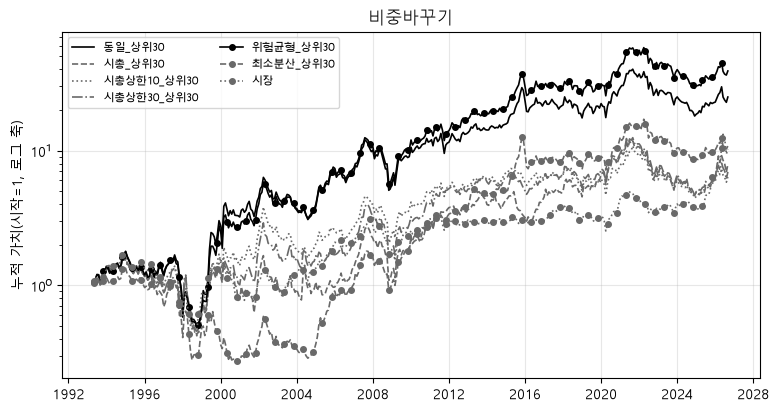

In [7]:
표 = 평가.성과표(R, F, [c for c in R if "_LS" in c])
표.insert(0, "이상값 보유", pd.Series({f"{b}_{g}": n for (b, g), n in 포.이상값보유(결과).items()}))  # +300% 종목-월 보유 건수(README 한계 '이상값 보유 칸')
평가.누적그림(R, 설정["이름"]);
표

## 7. 같은 기간 기준과 자동 비교 [건드리지 않는 칸]
같은 기간으로 우동호(2023) 재현과 시장을 돌려 나란히 놓는다. 무위험이자율과 전량교체 여부는 3번 칸 설정 것을 쓴다.
기준은 두 줄이다. **본문 설정**은 우동호 그대로(배당 빠진 수정주가, 결산 후 3개월), **같은 가격·재무시점**은 가격 계열과 재무시점까지 3번 칸 설정에 맞춘 것. 두 기준의 차이는 배당 포함 여부와 재무시점 차이에서 나온다. 실험 효과는 '같은 가격·재무시점' 줄과 비교한다.
기간 안에서 개월 수가 다를 수 있다(개월 칸 확인. 첫 리밸런싱에 종목이 없으면 그 구간은 빈칸).

In [8]:
기준 = {**포.우동호2023, "기간": 설정["기간"], "무위험": 설정["무위험"], "전량교체": 설정["전량교체"]}
기준들 = {f"기준:{기준['이름']}(본문 설정)": 기준, f"기준:{기준['이름']}(같은 가격·재무시점)": {**기준, "가격": 설정["가격"], "재무시점": 설정["재무시점"]}}
Fb = 평가.요인(포.기준일(기준), 기준)
기준표 = 평가.성과표(pd.DataFrame({k: 포.실행(v)["수익률"][("동일", "상위30")] for k, v in 기준들.items()} | {"기준:시장": Fb["시장"]}).dropna(how="all"), Fb)
비교 = pd.concat([표, 기준표])
비교[["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "Carhart α(월)", "Carhart t(NW)"]]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,Carhart α(월),Carhart t(NW)
동일_상위30,401.0000,23.9609,0.1011,0.3325,0.2965,-0.7191,0.1472,0.0070,1.7363
시총_상위30,401.0000,6.8921,0.0638,0.3688,0.2089,-0.7309,0.0754,0.0030,0.8463
시총상한10_상위30,401.0000,5.3594,0.0569,0.2985,0.1672,-0.7380,-0.0264,0.0008,0.2982
시총상한30_상위30,401.0000,5.9451,0.0597,0.3312,0.1868,-0.7160,0.0245,0.0012,0.4172
위험균형_상위30,401.0000,37.9568,0.1158,0.3312,0.3393,-0.7194,0.2001,0.0070,1.9025
최소분산_상위30,401.0000,9.7893,0.0738,0.3057,0.2240,-0.8005,0.0502,-0.0002,-0.0821
시장,401.0000,9.2700,0.0722,0.2673,0.2088,-0.7243,NaN,0.0000,NaN
기준:우동호2023_MF(본문 설정),401.0000,15.4885,0.0875,0.3102,0.2627,-0.6222,0.0952,0.0048,1.1560
기준:우동호2023_MF(같은 가격·재무시점),401.0000,23.9609,0.1011,0.3325,0.2965,-0.7191,0.1472,0.0070,1.7363
기준:시장,401.0000,9.2700,0.0722,0.2673,0.2088,-0.7243,NaN,0.0000,NaN


## 8. 확인 [건드리지 않는 칸]
리밸런싱마다 단계별 남은 종목 수, 지표별 빈칸 수, 빈칸 때문에 빠진 수, 편입 수.

In [9]:
결과["기록"].T

기준일,1993-04-01,1994-04-01,1995-04-01,1996-04-01,1997-04-01,1998-04-01,1999-04-01,2000-04-03,2001-04-02,2002-04-01,...,2017-04-03,2018-04-02,2019-04-01,2020-04-01,2021-04-01,2022-04-01,2023-04-03,2024-04-01,2025-04-01,2026-04-01
가격있음,793,802,848,885,1270,1308,1239,1419,1511,1670,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
시장,793,802,848,885,1270,1308,1239,1419,1511,1670,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
쓰지말것,793,802,848,885,1270,1308,1239,1418,1511,1670,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
보통주,653,662,690,720,1081,1131,1056,1214,1312,1471,...,1992,2044,2121,2210,2298,2373,2456,2558,2640,2660
금융업,566,574,595,624,931,988,944,1102,1206,1376,...,1865,1851,1915,2021,2106,2179,2247,2335,2402,2437
투자기구,566,574,595,624,931,988,944,1102,1206,1375,...,1842,1841,1903,2008,2090,2158,2224,2312,2379,2414
결산월,478,488,508,536,816,871,825,907,1039,1233,...,1802,1805,1866,1968,2050,2120,2187,2276,2346,2384
거래정지,478,488,506,533,815,867,812,874,1007,1200,...,1766,1767,1807,1874,1948,2024,2126,2191,2260,2292
빈칸:ROC,81,86,84,87,245,247,209,185,192,225,...,147,147,151,40,33,32,39,46,51,52
빈칸:EY,7,12,10,9,75,71,44,23,9,28,...,124,124,132,20,14,14,14,24,27,28


## 9. 저장 [건드리지 않는 칸]
설정과 결과를 `연구/결과/이름_날짜_실험명.csv`에 남긴다. 같은 이름이 있으면 뒤에 번호를 붙인다(덮어쓰지 않음).

In [10]:
out = Path.cwd() / "결과"
f = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}.csv"
i = 1
while f.exists():
    f, i = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}_{i}.csv", i + 1
비교.assign(실험기록=json.dumps(실험, ensure_ascii=False), 설정=json.dumps(설정, ensure_ascii=False, default=str)).to_csv(f, encoding="utf-8-sig")
print("저장:", f)

저장: D:\26-2_데이터기반투자전략\과제02\과제02_백테스트\연구\결과\이로운_2026-11-02_비중바꾸기_2.csv


## 10. 회전율·거래비용 전후 [실험 칸]
- **회전율** = 리밸런싱 때 산 비중의 합(처음 매수 = 1이라 첫 리밸런싱은 평균에서 뺀다). 리밸런싱 사이 값이 변해 생긴 비중 차이도 들어간다.
- **비용 전** = 같은 설정에서 거래비용만 0. 둘의 연환산 차이가 비용으로 잃은 연수익이다.
- **편입 수** = 비중이 0.1%보다 큰 종목 수. 위험균형(12개월)·최소분산(36개월)은 이력이 모자란 종목이 빠지고, 최소분산은 비중 0인 종목이 생긴다.

In [11]:
결과0 = 포.실행({**설정, "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)})
연 = lambda r: (1 + r.dropna()).prod() ** (12 / r.dropna().size) - 1
비용표 = pd.DataFrame({b: {"평균 회전율(리밸런싱당)": 결과["회전율"][(b, "상위30")].iloc[1:].mean(),
                         "편입 수 평균": pd.Series([(w > 0.001).sum() for w in 결과["보유"][(b, "상위30")].values()]).mean(),
                         "편입 수 최소": min((w > 0.001).sum() for w in 결과["보유"][(b, "상위30")].values()),
                         "최대 비중 평균": pd.Series([w.max() for w in 결과["보유"][(b, "상위30")].values()]).mean(),
                         "연환산(비용 전)": 연(결과0["수익률"][(b, "상위30")]), "연환산(비용 후)": 연(결과["수익률"][(b, "상위30")])} for b in 설정["비중"]}).T
비용표["비용으로 잃은 연수익"] = 비용표["연환산(비용 전)"] - 비용표["연환산(비용 후)"]
display(비용표)
평가.성과표(pd.DataFrame({f"{b}(비용 전)": 결과0["수익률"][(b, "상위30")] for b in 설정["비중"]}).dropna(how="all"), F)[["누적", "연환산", "표준편차(연)", "샤프", "MDD"]]

,평균 회전율(리밸런싱당),편입 수 평균,편입 수 최소,최대 비중 평균,연환산(비용 전),연환산(비용 후),비용으로 잃은 연수익
동일,0.8293,30.0000,30.0000,0.0333,0.1129,0.1011,0.0118
시총,0.7753,26.3529,4.0000,0.4814,0.0745,0.0638,0.0107
시총상한10,0.7963,29.8824,28.0000,0.1000,0.0678,0.0569,0.0109
시총상한30,0.7790,29.7647,28.0000,0.2650,0.0704,0.0597,0.0107
위험균형,0.8357,27.5882,15.0000,0.0678,0.1279,0.1158,0.0121
최소분산,0.8634,19.2941,5.0000,0.1227,0.0858,0.0738,0.0120


,누적,연환산,표준편차(연),샤프,MDD
동일(비용 전),34.6831,0.1129,0.3339,0.3287,-0.7073
시총(비용 전),10.0275,0.0745,0.3708,0.2363,-0.7204
시총상한10(비용 전),7.9640,0.0678,0.2999,0.2018,-0.7275
시총상한30(비용 전),8.7180,0.0704,0.3326,0.2174,-0.7044
위험균형(비용 전),54.8433,0.1279,0.3326,0.3717,-0.7074
최소분산(비용 전),14.6501,0.0858,0.3073,0.2604,-0.7870


## 11. 요약표용 저장 [실험 칸]

In [12]:
S = 결과["수익률"].copy()
S.columns = pd.MultiIndex.from_tuples([(f"비중바꾸기 MF {g}", b) for b, g in S])
평가.저장(S, F, "연구_이로운_비중바꾸기", 이상값={(f"비중바꾸기 MF {g}", b): n for (b, g), n in 포.이상값보유(결과).items()})
수렴 = pd.DataFrame(포.최소분산기록)
print("최소분산 SLSQP:", len(수렴), "번 풂, 수렴 안 됨", int((~수렴["수렴"]).sum()) if len(수렴) else 0, "번")
list(S)

최소분산 SLSQP: 68 번 풂, 수렴 안 됨 0 번


[('비중바꾸기 MF 상위30', '동일'),
 ('비중바꾸기 MF 상위30', '시총'),
 ('비중바꾸기 MF 상위30', '시총상한10'),
 ('비중바꾸기 MF 상위30', '시총상한30'),
 ('비중바꾸기 MF 상위30', '위험균형'),
 ('비중바꾸기 MF 상위30', '최소분산')]